### Import Libraries

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

# to load data set from Hugging Face
from datasets import load_dataset

C:\Users\sahas\.conda\envs\emotion_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load Dataset

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')

In [3]:
emotion_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [4]:
emotion_dataset['train']

Dataset({
    features: ['text', 'label'],
    num_rows: 16000
})

In [5]:
train_text = emotion_dataset['train']['text']

In [6]:
train_text

Column(['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'im grabbing a minute to post i feel greedy wrong', 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property', 'i am feeling grouchy', ...])

In [7]:
train_label = emotion_dataset['train']['label']

In [8]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [9]:
label_name = emotion_dataset['train'].features['label'].names

In [10]:
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [11]:
test_text = emotion_dataset['test']['text']

In [12]:
test_text

Column(['im feeling rather rotten so im not very ambitious right now', 'im updating my blog because i feel shitty', 'i never make her separate from me because i don t ever want her to feel like i m ashamed with her', 'i left with my bouquet of red and yellow tulips under my arm feeling slightly more optimistic than when i arrived', 'i was feeling a little vain when i did this one', ...])

In [13]:
test_label = emotion_dataset['test']['label']

In [14]:
test_label

Column([0, 0, 0, 1, 0, ...])

In [15]:
for i in train_label:
    print(label_name[i])

sadness
sadness
anger
love
anger
sadness
surprise
fear
joy
love
sadness
joy
anger
sadness
joy
joy
sadness
sadness
sadness
fear
anger
fear
joy
joy
anger
sadness
sadness
sadness
anger
joy
joy
fear
surprise
anger
joy
joy
joy
joy
anger
joy
joy
joy
joy
joy
sadness
sadness
joy
love
joy
anger
joy
sadness
anger
fear
joy
sadness
sadness
surprise
joy
joy
joy
love
fear
fear
surprise
anger
anger
sadness
love
joy
sadness
sadness
joy
sadness
sadness
sadness
joy
joy
joy
anger
sadness
anger
anger
anger
joy
joy
joy
joy
sadness
fear
love
anger
sadness
anger
love
sadness
joy
joy
sadness
anger
love
joy
joy
joy
sadness
joy
joy
joy
joy
sadness
joy
joy
love
sadness
sadness
joy
joy
sadness
joy
joy
fear
fear
fear
sadness
love
joy
joy
love
fear
surprise
joy
joy
joy
joy
anger
fear
joy
anger
love
anger
sadness
joy
sadness
anger
joy
surprise
sadness
anger
anger
sadness
joy
fear
joy
joy
fear
sadness
surprise
surprise
joy
anger
fear
anger
sadness
anger
sadness
fear
sadness
joy
surprise
fear
joy
anger
joy
anger
joy
f

In [16]:
df_train = pd.DataFrame(
    {
        'text' : train_text, 
        'label' : (label_name[i] for i in train_label)
    }
)

In [17]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [18]:
df_train.sample()

,text,label
14626,i feel like an abused puppy dog,sadness


In [19]:
df_test = pd.DataFrame(
    {
        'text' : test_text, 
        'label' : (label_name[i] for i in test_label)
    }
)

In [20]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [21]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

In [22]:
df_test.isnull().sum()

text     0
label    0
dtype: int64

## EDA

<Axes: xlabel='label', ylabel='count'>

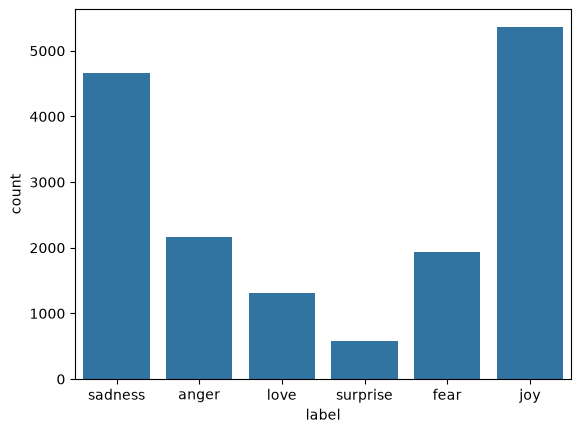

In [23]:
sns.countplot(x='label',data=df_train)

In [24]:
df_train['label'].value_counts()

label
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

<Axes: xlabel='label', ylabel='count'>

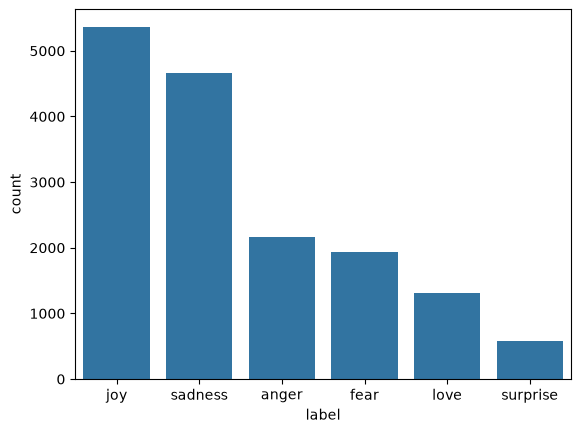

In [25]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)

## Data Preprocessing help of NLP

In [26]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

In [27]:
train_sequence = tokenizer.texts_to_sequences(df_train['text']) 
train_sequence

[[2, 139, 3, 679],
 [2,
  40,
  101,
  60,
  8,
  15,
  494,
  5,
  15,
  3496,
  553,
  32,
  60,
  61,
  128,
  148,
  76,
  1480,
  4,
  22,
  1255],
 [17, 3060, 7, 1149, 5, 286, 2, 3, 495, 438],
 [2, 24, 165, 8, 665, 27, 6, 4158, 2, 59, 47, 9, 13, 22, 72, 30, 6, 3497],
 [2, 24, 8, 1065],
 [73, 48, 8, 7, 56, 521, 319, 328, 158, 161, 9, 20],
 [73,
  48,
  329,
  35,
  7401,
  35,
  196,
  7402,
  888,
  4,
  73,
  2475,
  1384,
  7,
  159,
  1885,
  19,
  2,
  117,
  3,
  14,
  15,
  455],
 [2, 3, 29, 439, 27, 78, 29, 7, 1686, 35, 29, 760, 29, 7, 193, 267, 374],
 [2,
  21,
  48,
  25,
  5260,
  16,
  215,
  2,
  3,
  9,
  5260,
  99,
  5261,
  135,
  4,
  132,
  7,
  1038,
  4159],
 [2, 3, 666, 94],
 [2, 3, 14, 2, 21, 5, 80, 6, 733, 2, 93, 544, 304, 84],
 [2,
  39,
  3,
  9,
  483,
  22,
  7,
  530,
  440,
  4,
  9,
  2,
  40,
  920,
  5,
  21,
  69,
  840,
  10,
  1886,
  3061],
 [2, 70, 13, 90, 6, 5262, 52, 10, 193, 5, 3, 610],
 [2, 3, 339, 456, 2, 93, 32, 4160],
 [2,
  21,
  4161,

In [28]:
test_sequenece = tokenizer.texts_to_sequences(df_test['text']) 
test_sequenece

[[17, 8, 203, 715, 15, 17, 26, 46, 5595, 114, 58],
 [17, 1, 11, 243, 37, 2, 3, 469],
 [2,
  145,
  80,
  68,
  2971,
  60,
  18,
  37,
  2,
  104,
  43,
  165,
  67,
  68,
  5,
  3,
  14,
  2,
  93,
  406,
  25,
  68],
 [2,
  172,
  25,
  11,
  1,
  10,
  873,
  4,
  5366,
  1,
  736,
  11,
  1518,
  8,
  351,
  38,
  608,
  95,
  34,
  2,
  1973],
 [2, 20, 8, 7, 56, 654, 34, 2, 127, 23, 71],
 [2, 131, 421, 106, 7, 1515, 1439, 153, 2, 39, 26, 3, 498],
 [2, 144, 974, 34, 33, 6, 228, 10, 7, 5667, 388],
 [2,
  962,
  161,
  2,
  9809,
  5,
  7,
  635,
  25,
  7,
  782,
  76,
  20,
  12,
  160,
  576,
  2771,
  4,
  1,
  865,
  6,
  1824,
  2,
  121,
  21,
  48,
  8,
  16,
  180,
  294,
  106,
  6,
  3471,
  1658,
  33,
  6,
  1858,
  10,
  3559],
 [2, 14, 5, 21, 6, 224, 1, 8, 29, 7, 1600, 723, 5, 113, 54, 59, 518, 292],
 [2,
  1,
  2,
  3,
  796,
  288,
  4,
  2369,
  1,
  108,
  2,
  338,
  24,
  19,
  125,
  129,
  79,
  118,
  48,
  7,
  202,
  4,
  17,
  27,
  29,
  1047,
  29,
  7,
 

In [29]:
# check the max length 

print(max(len(seq) for seq in train_sequence))

66


In [30]:
padded_train_sequence = pad_sequences(train_sequence,maxlen=66,padding='post', truncating='post')

In [31]:
padded_train_sequence

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]],
      shape=(16000, 66), dtype=int32)

In [33]:
padded_test_sequence = pad_sequences(test_sequenece ,maxlen=66,padding='post', truncating='post')

In [34]:
padded_test_sequence

array([[ 17,   8, 203, ...,   0,   0,   0],
       [ 17,   1,  11, ...,   0,   0,   0],
       [  2, 145,  80, ...,   0,   0,   0],
       ...,
       [  2,   3,   9, ...,   0,   0,   0],
       [ 17,   8,  38, ...,   0,   0,   0],
       [  2,   3,  36, ...,   0,   0,   0]], shape=(2000, 66), dtype=int32)

In [35]:
train_labels = np.array(train_label)
test_labels  = np.array(test_label)

In [36]:
train_labels

array([0, 0, 3, ..., 1, 3, 0], shape=(16000,))

In [37]:
test_labels

array([0, 0, 0, ..., 1, 1, 4], shape=(2000,))

In [38]:
num_classes = len(np.unique(train_labels))
num_classes

6

In [39]:
print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")

Vocabulary Size: 15213
Max Sentence Length: 66


## Shared Training Utilities

weight = (total samples)/(number of classes * sample in that class)

weight(Sadness) = 16000 / (6* 4666)
                = 0.5715

weight(Surprise) = 16000 / (6* 572) = 4.662

In [40]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [41]:
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [42]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

## Build Simple Model

##### Simple RNN

In [48]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [49]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.1629 - loss: 2.0764 - val_accuracy: 0.1625 - val_loss: 1.7774
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1476 - loss: 1.9080 - val_accuracy: 0.2840 - val_loss: 1.7387
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1416 - loss: 1.8309 - val_accuracy: 0.0480 - val_loss: 1.8231
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1353 - loss: 1.8090 - val_accuracy: 0.3060 - val_loss: 1.8000
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.1466 - loss: 1.8032 - val_accuracy: 0.0690 - val_loss: 1.7934
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2840 - loss: 1.7387
RNN Loss: 1.7387210130691528
RNN Accuracy: 0.2840000092983246


##### LSTM

In [50]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

C:\Users\sahas\.conda\envs\emotion_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [51]:
lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [52]:
lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 34s 61ms/step - accuracy: 0.1454 - loss: 1.7953 - val_accuracy: 0.0330 - val_loss: 1.8129
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.1290 - loss: 1.7938 - val_accuracy: 0.2905 - val_loss: 1.7853
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 31s 61ms/step - accuracy: 0.1575 - loss: 1.7934 - val_accuracy: 0.0405 - val_loss: 1.7983
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.1421 - loss: 1.7939 - val_accuracy: 0.0340 - val_loss: 1.7985
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 61ms/step - accuracy: 0.1364 - loss: 1.7925 - val_accuracy: 0.2910 - val_loss: 1.7634
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.1471 - loss: 1.7927 - val_accuracy: 0.3360 - val_loss: 1.7864
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - accuracy: 0.1523 - loss: 1.7930 - val_accuracy: 0.0340 - val_loss: 1.8063
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 60ms/step - accuracy: 0.1461 - loss: 1.7929 - 

In [53]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.2910 - loss: 1.7634
LSTM Loss: 1.7633644342422485
LSTM Accuracy: 0.29100000858306885


##### GRU

In [54]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

C:\Users\sahas\.conda\envs\emotion_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [55]:
gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [56]:
gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 58ms/step - accuracy: 0.1544 - loss: 1.7965 - val_accuracy: 0.1120 - val_loss: 1.7997
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 57ms/step - accuracy: 0.1544 - loss: 1.7956 - val_accuracy: 0.1120 - val_loss: 1.7789
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 57ms/step - accuracy: 0.1458 - loss: 1.7950 - val_accuracy: 0.0795 - val_loss: 1.7966
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 58ms/step - accuracy: 0.1488 - loss: 1.7947 - val_accuracy: 0.1120 - val_loss: 1.8091
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 57ms/step - accuracy: 0.1469 - loss: 1.7945 - val_accuracy: 0.0795 - val_loss: 1.7931


In [57]:
gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.1120 - loss: 1.7789
GRU Loss: 1.7789164781570435
GRU Accuracy: 0.1120000034570694


### Ranking & Selection of Simple Models

In [58]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df

,Model,Test Loss,Test Accuracy
1,LSTM,1.763364,0.291
0,RNN,1.738721,0.284
2,GRU,1.778916,0.112


## Build Complex Model

##### Advanced Bidirectional GRU

In [60]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
    #Why i used num_classes in output layer and what will i get from this.
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

C:\Users\sahas\.conda\envs\emotion_env\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [61]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 93ms/step - accuracy: 0.5810 - loss: 1.0403 - val_accuracy: 0.8940 - val_loss: 0.3432
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.9182 - loss: 0.2350 - val_accuracy: 0.9195 - val_loss: 0.2349
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.9438 - loss: 0.1474 - val_accuracy: 0.9275 - val_loss: 0.2040
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.9607 - loss: 0.0986 - val_accuracy: 0.9145 - val_loss: 0.2757
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.9696 - loss: 0.0786 - val_accuracy: 0.9140 - val_loss: 0.2870
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 94ms/step - accuracy: 0.9746 - loss: 0.0714 - val_accuracy: 0.9185 - val_loss: 0.2683


In [62]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9275 - loss: 0.2040
BiGRU Loss: 0.20398715138435364
BiGRU Accuracy: 0.9275000095367432


## Overall Evaluation & Bias Analysis

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step


<Axes: >

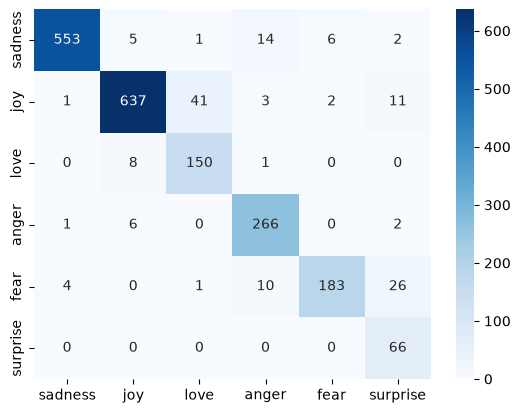

In [67]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_name, yticklabels=label_name)


In [65]:
BiGRU_predictions = BiGRU.predict(padded_test_sequence)

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step


## Final Predictions

In [71]:
sample_texts = [
    "I am so so happy right now.",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


In [72]:
for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_name[sample_predictions[i]]}')

Text: I am so so happy right now.
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


## Save Model & Tokenizer

In [73]:
import os
import pickle

model_dir = r"E:\Deploy\End to end project\Emotional Analysis\Models Exported"
os.makedirs(model_dir, exist_ok=True)

# Save the trained BiGRU model
model_path = os.path.join(model_dir, "BiGRU_Modle.keras")
BiGRU.save(model_path)

# Save the tokenizer
tokenizer_path = os.path.join(model_dir, "tokenizer.pkl")
with open(tokenizer_path, "wb") as file:
    pickle.dump(tokenizer, file)

print("Model saved to", model_path)
print("Tokenizer saved to", tokenizer_path)

Model saved to E:\Deploy\End to end project\Emotional Analysis\Models Exported\BiGRU_Modle.keras
Tokenizer saved to E:\Deploy\End to end project\Emotional Analysis\Models Exported\tokenizer.pkl
